# Full Real-Data Kernel Fit

Fit one reusable spatiotemporal GP to **all 980 aligned observations**. Clock synchronization with zero additional offset is accepted as an experimental assumption. This full-data model is stored separately from the minimal-test models. There is no independent test set for this fit.

The [README](README.md) describes the source data, exact units, dependencies and model-loading example.

In [1]:
from pathlib import Path
import json, hashlib, html
from IPython.display import display, HTML, Image
root=Path.cwd()
run=root/'result'/json.loads((root/'result'/'latest.json').read_text())['run']
hp=json.loads((run/'hyperparameters.json').read_text())
rows=[['East lengthscale (m)',hp['lengthscales_m_m_s'][0]],
      ['North lengthscale (m)',hp['lengthscales_m_m_s'][1]],
      ['Time lengthscale (s)',hp['lengthscales_m_m_s'][2]],
      ['Signal variance (°C²)',hp['output_variance_c2']],
      ['Observation-noise variance (°C²)',hp['noise_variance_c2']],
      ['Observation-noise SD (°C)',hp['noise_std_c']],
      ['Learned mean (°C)',hp['mean_c']],['Training observations',hp['training_observations']]]
display(HTML('<table><tr><th>Parameter</th><th>Value</th></tr>'+''.join(
    '<tr><td>'+html.escape(k)+'</td><td>'+str(round(v,6))+'</td></tr>' for k,v in rows)+'</table>'))
print('Model:',run/'spatiotemporal_gp.pt')
print('Kernel: ConstantMean + ScaleKernel(RBF_ARD_xy × RBF_t), Gaussian likelihood')

Parameter,Value
East lengthscale (m),3.59815
North lengthscale (m),21.093915
Time lengthscale (s),21.135643
Signal variance (°C²),0.058976
Observation-noise variance (°C²),0.000865
Observation-noise SD (°C),0.029416
Learned mean (°C),27.152507
Training observations,980


Model: C:\Users\Administrator\Documents\4RP3\Code\ROS_simulation\Trained_Real_Data_Kernel\result\full_fit_20261105T031701003839Z\spatiotemporal_gp.pt
Kernel: ConstantMean + ScaleKernel(RBF_ARD_xy × RBF_t), Gaussian likelihood


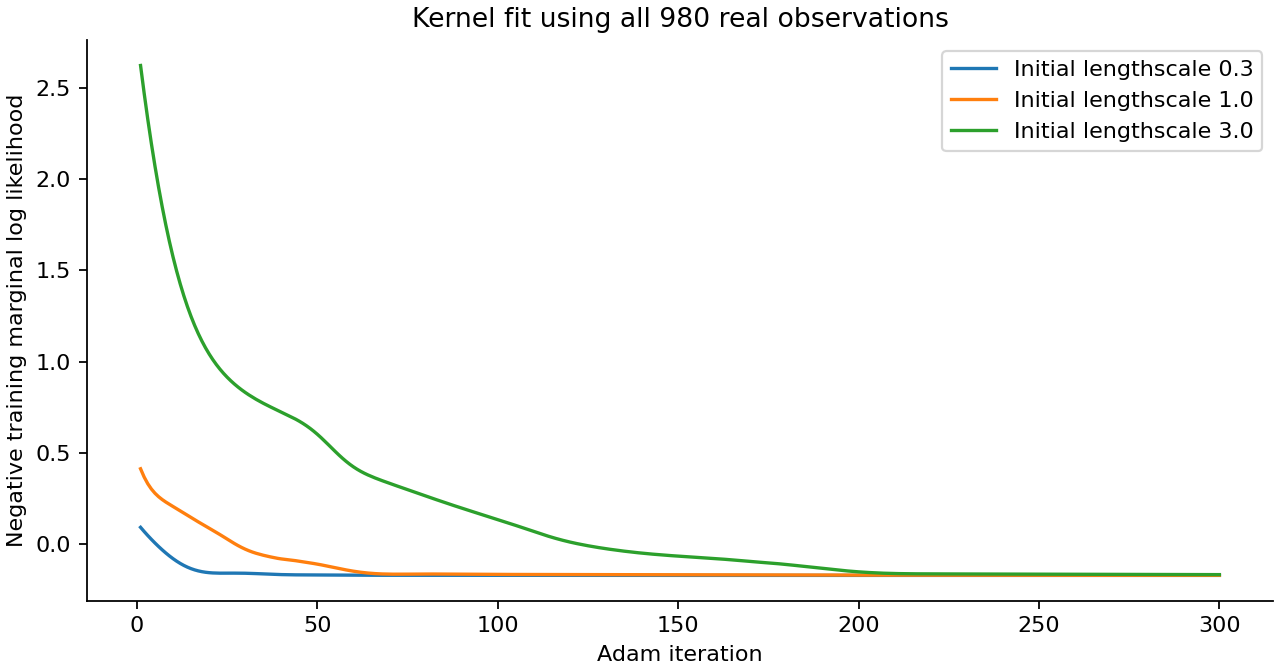

In [2]:
display(Image(filename=str(root/'result'/'figures'/'full_data_training.png'),embed=True))

## Verification and interpretation

The initialization is selected using training marginal likelihood. These curves measure training optimization, not held-out accuracy. The checkpoint includes the fitted kernel, all training observations and the scaler. Original coordinate and time references must be retained when querying it.

In [3]:
manifest=json.loads((run/'manifest.json').read_text())
for name,expected in manifest['outputs'].items():
    assert hashlib.sha256((run/name).read_bytes()).hexdigest()==expected,name
assert hashlib.sha256((run/'input_samples.csv').read_bytes()).hexdigest()==manifest['input_sha256']
assert hashlib.sha256((root/'testing_code'/'gp_model.py').read_bytes()).hexdigest()==manifest['gp_model_sha256']
v=json.loads((run/'verification.json').read_text()); assert v['passed']
print(len(v['checks']),'numerical/data checks passed. Saved model and loader hashes match.')
print('The worker checked reload predictions and independent NumPy/SciPy RBF/Cholesky calculations.')
print('This full-data fit has no independent accuracy estimate; previous test scores remain separate.')

13 numerical/data checks passed. Saved model and loader hashes match.
The worker checked reload predictions and independent NumPy/SciPy RBF/Cholesky calculations.
This full-data fit has no independent accuracy estimate; previous test scores remain separate.


## Result

The full-data kernel and conditioned GP are saved and loadable. They can be used for the next stage under the recorded experimental assumptions. Fit completion does not establish long-horizon accuracy or unique separation of spatial and temporal structure from one mobile run. Keep any new validation observations separate from these training data.